# Détection du diabète : comparaison de modèles de classification

**Objectif** : prédire si une patiente est diabétique (`Outcome = 1`) à partir de mesures médicales simples, et comparer quatre familles de modèles : régression logistique, SVM, arbre de décision et réseau de neurones.

**Données** : jeu *Pima Indians Diabetes* (National Institute of Diabetes and Digestive and Kidney Diseases). Il contient 768 femmes d'au moins 21 ans, d'origine amérindienne Pima, et aucune ligne en double.

| Variable | Description | Unité |
|---|---|---|
| `Pregnancies` | Nombre de grossesses | – |
| `Glucose` | Glycémie 2 h après un test de tolérance au glucose (HGPO) | mg/dL |
| `BloodPressure` | Pression artérielle diastolique | mm Hg |
| `SkinThickness` | Épaisseur du pli cutané au triceps | mm |
| `Insulin` | Insuline sérique à 2 h | µU/mL |
| `BMI` | Indice de masse corporelle | kg/m² |
| `DiabetesPedigreeFunction` | Score d'antécédents familiaux de diabète | – |
| `Age` | Âge | années |
| `Outcome` | **Cible** : 1 = diabétique, 0 = non diabétique | – |

**Plan du notebook**

1. Chargement et premier aperçu
2. Valeurs manquantes déguisées en zéros
3. Analyse exploratoire
4. Premier essai de modélisation (découpage unique 70/30)
5. Réglage des hyperparamètres et comparaison en validation croisée imbriquée
6. Conclusion

In [112]:
%pip install pandas matplotlib seaborn scikit-learn numpy missingno

Note: you may need to restart the kernel to use updated packages.


## 1. Chargement et premier aperçu

In [113]:
import pandas as pd

df = pd.read_csv('data/diabetes.csv')

df.head(10)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


In [114]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


Toutes les colonnes sont numériques et `info()` n'annonce **aucune valeur manquante**. Les statistiques descriptives ci-dessous montrent pourtant que ce n'est pas le cas.

In [115]:
df.describe().round(2)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,3.85,120.89,69.11,20.54,79.80,31.99,0.47,33.24,0.35
std,3.37,31.97,19.36,15.95,115.24,7.88,0.33,11.76,0.48
min,0.00,0.00,0.00,0.00,0.00,0.00,0.08,21.00,0.00
25%,1.00,99.00,62.00,0.00,0.00,27.30,0.24,24.00,0.00
50%,3.00,117.00,72.00,23.00,30.50,32.00,0.37,29.00,0.00
75%,6.00,140.25,80.00,32.00,127.25,36.60,0.63,41.00,1.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00


## 2. Valeurs manquantes déguisées en zéros

Le minimum vaut **0** pour `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` et `BMI`. Ces valeurs sont physiologiquement impossibles chez une personne vivante (glycémie nulle, IMC nul…). Ce sont des **mesures manquantes codées par 0**.

On les remplace par `NaN` pour pouvoir les compter. `Pregnancies` n'est pas concernée, puisque 0 grossesse est une valeur légitime.

In [116]:
import numpy as np

cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[cols] = df[cols].replace(0, np.nan)


df.isnull().sum()

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Le problème est massif pour deux variables :

| Variable | Manquants | Part |
|---|---|---|
| `Insulin` | 374 | **48,7 %** |
| `SkinThickness` | 227 | **29,6 %** |
| `BloodPressure` | 35 | 4,6 % |
| `BMI` | 11 | 1,4 % |
| `Glucose` | 5 | 0,7 % |

Le graphique `missingno` ci-dessous visualise le taux de remplissage de chaque colonne.

<Axes: >

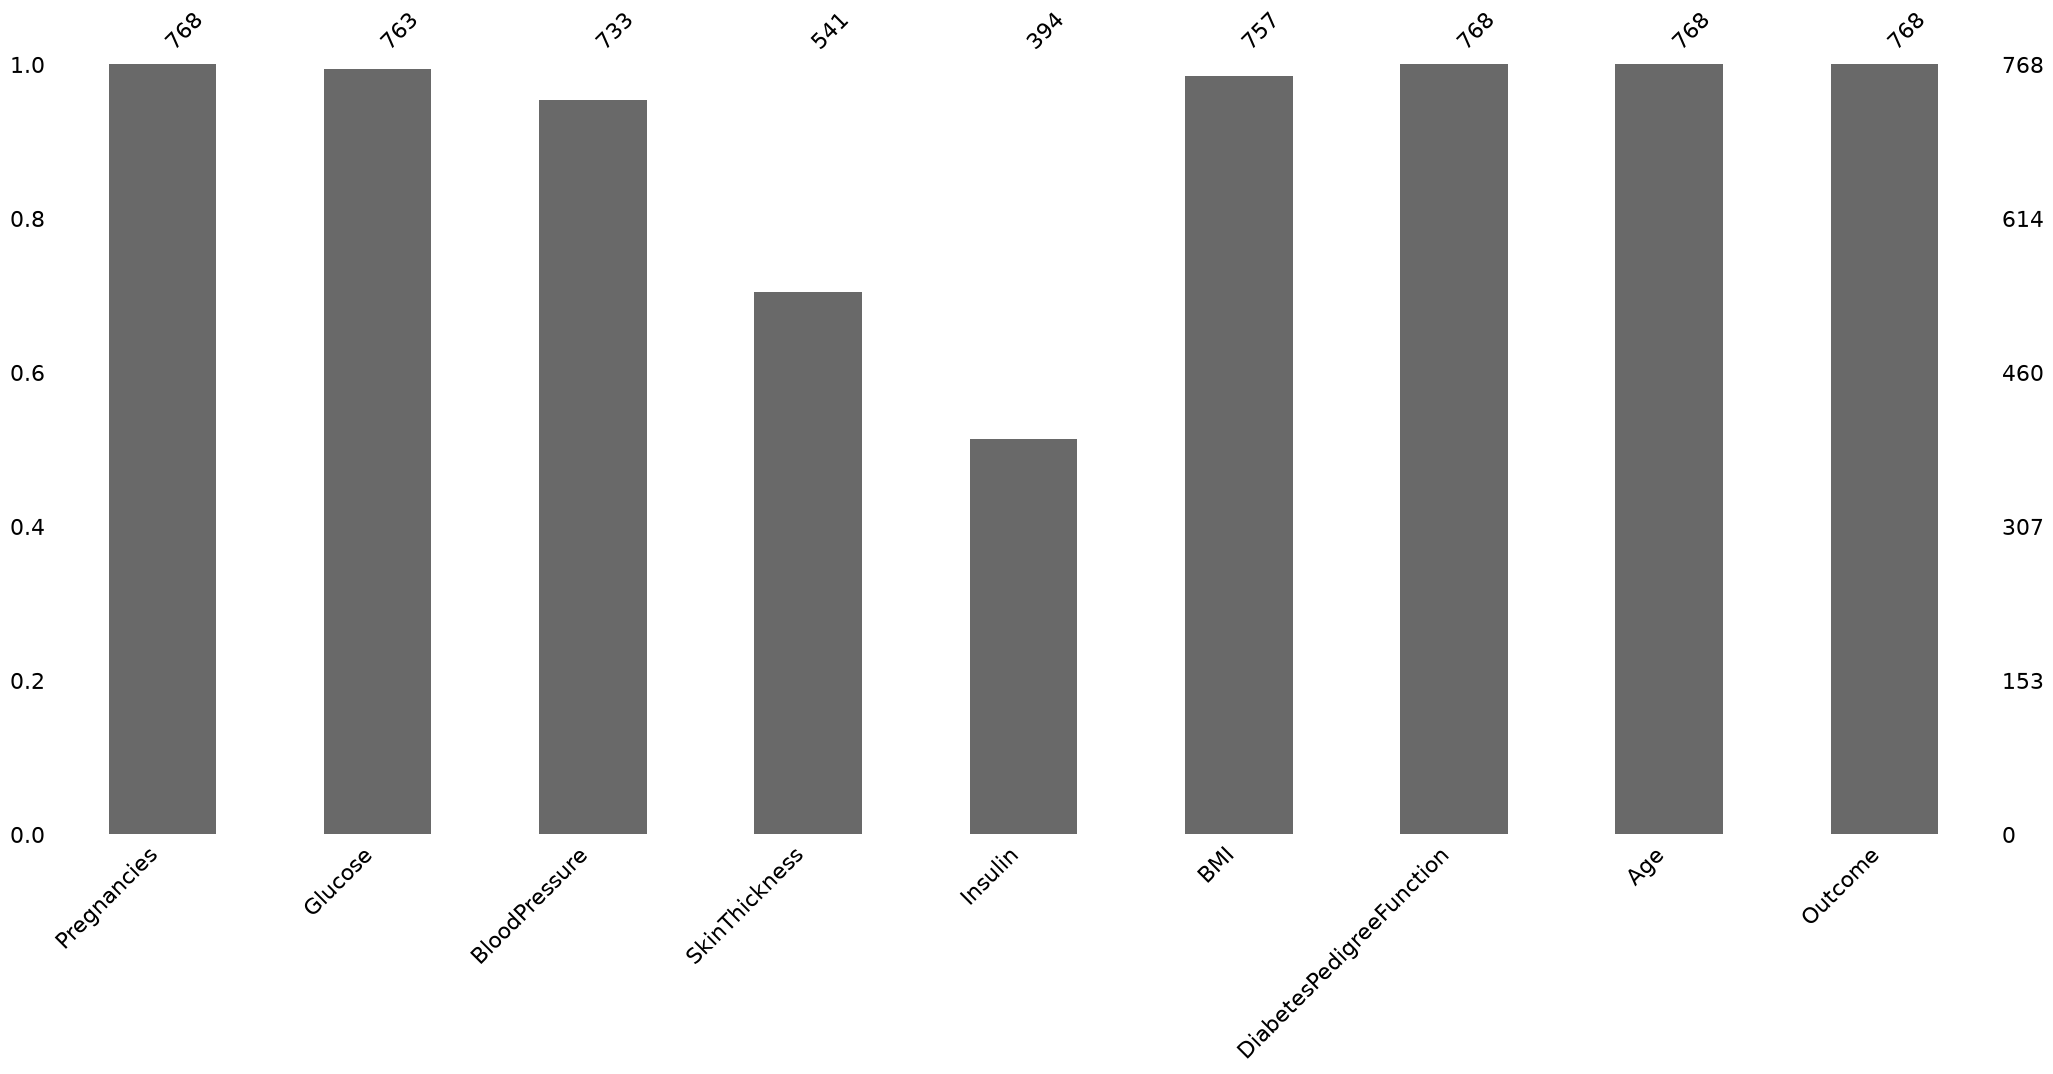

In [117]:
import missingno as msno

msno.bar(df)


### Imputation par la médiane

On remplace chaque valeur manquante par la **médiane** de sa colonne. La médiane est préférée à la moyenne car elle est peu sensible aux valeurs extrêmes (`Insulin` monte jusqu'à 846).

⚠️ **Limites de ce choix**

- **Pic artificiel** : pour `Insulin`, près de la moitié des patientes reçoivent la même valeur (125). Cela crée un pic visible dans les histogrammes et écrase l'information de cette variable.
- **Fuite d'information** : ici la médiane est calculée sur **tout** le jeu de données, avant le découpage entraînement/test. Les données de test influencent donc légèrement l'entraînement. La section 5 corrige ce point en plaçant l'imputation **dans le pipeline**.

In [118]:
for col in cols:
    df[col] = df[col].fillna(df[col].median())

df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

## 3. Analyse exploratoire

### Distribution de chaque variable

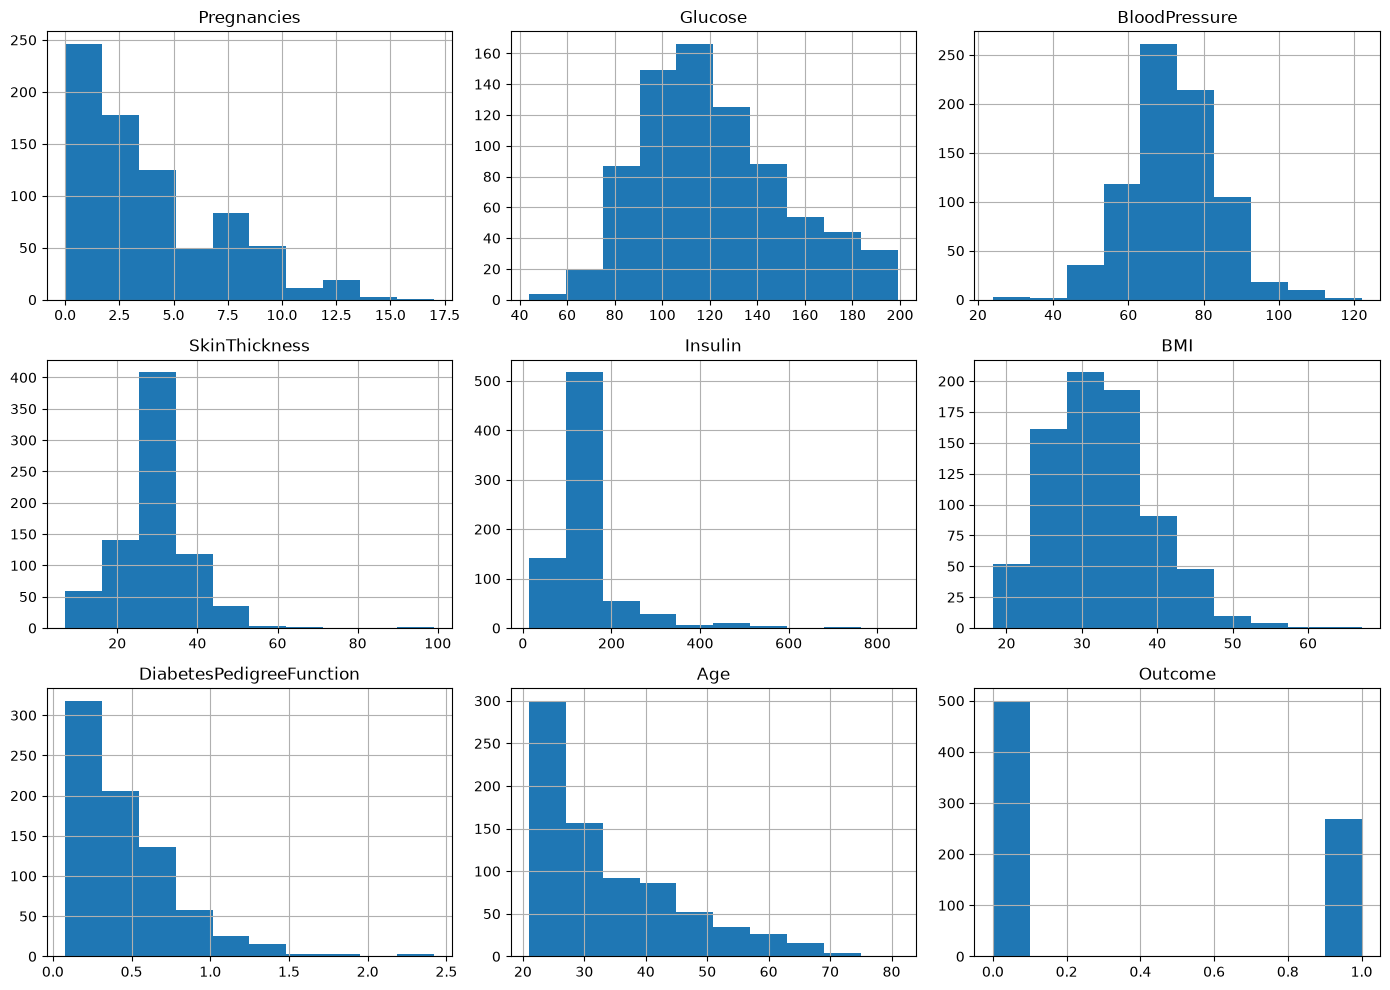

In [119]:
import matplotlib.pyplot as plt

df.hist(figsize=(14, 10))
plt.tight_layout()
plt.show()

**Lecture des histogrammes**

- **Asymétrie à droite** : `Insulin` (coefficient d'asymétrie 3,4), `DiabetesPedigreeFunction` (1,9) et `Age` (1,1) ont une longue traîne de valeurs élevées. La population est surtout jeune : la moitié des patientes a moins de 29 ans.
- **Distributions proches d'une cloche** : `Glucose`, `BloodPressure` et `BMI`.
- **Pics à la médiane** : `Insulin` et `SkinThickness` montrent un pic à la valeur médiane. Il est créé par l'imputation, pas par les données réelles.

Les échelles sont très différentes d'une variable à l'autre (de 0,08 à 846). Il faudra donc **normaliser** les données pour les modèles sensibles aux distances ou aux gradients : SVM, réseau de neurones, régression logistique.

### Comparaison des variables selon le diagnostic

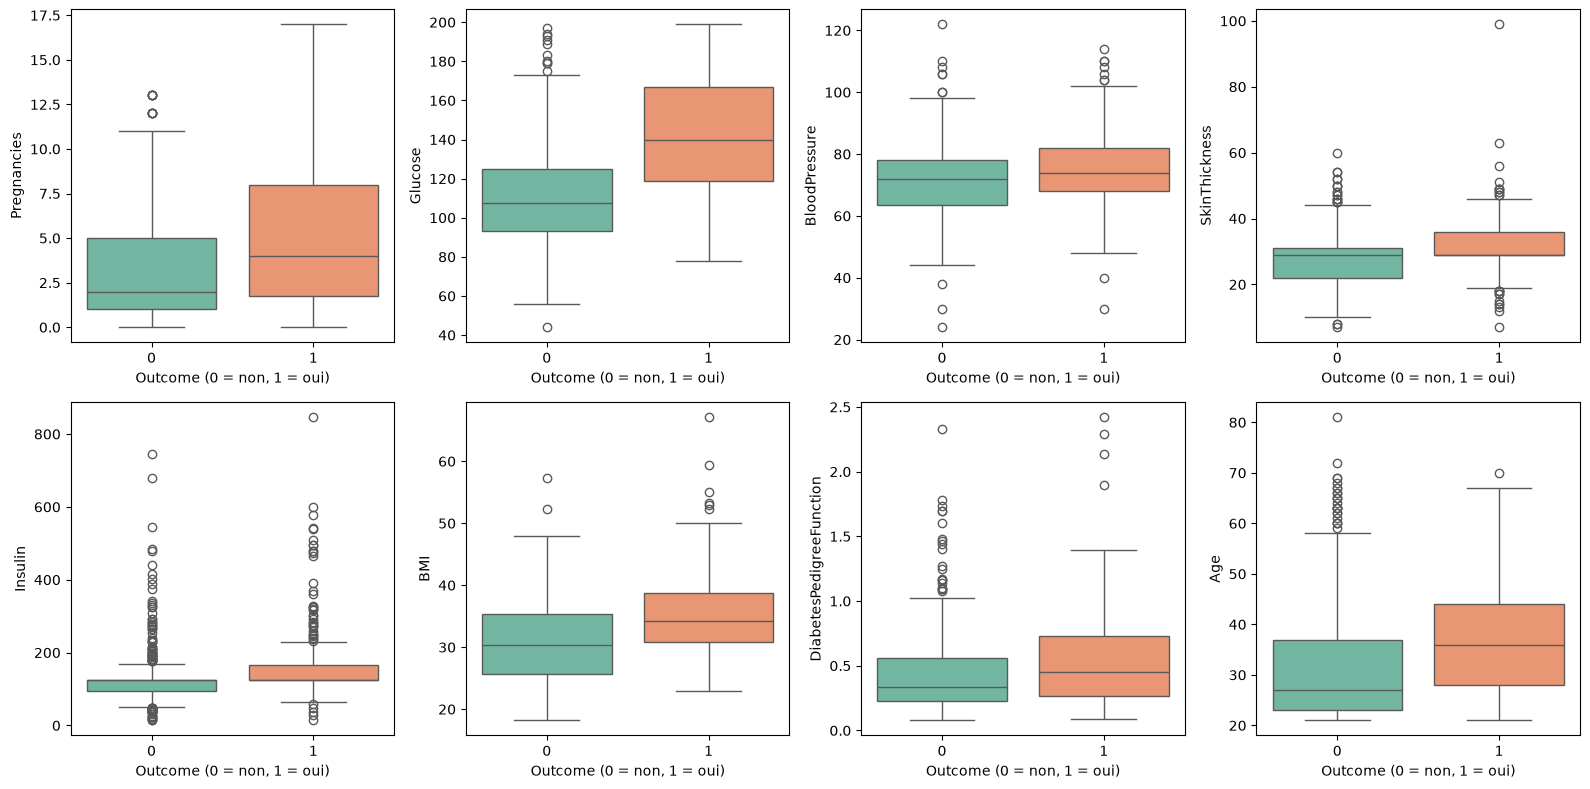

In [120]:
import seaborn as sns
features = df.columns.drop('Outcome')

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.flat, features):
    sns.boxplot(data=df, x='Outcome', y=col, ax=ax, hue='Outcome',
                palette='Set2', legend=False)
    ax.set_xlabel('Outcome (0 = non, 1 = oui)')

plt.tight_layout()
plt.show()


**Lecture des boîtes à moustaches**

- **`Glucose`** sépare le mieux les deux groupes : la médiane passe de 107,5 mg/dL (non diabétiques) à 140 mg/dL (diabétiques). C'est attendu, puisque le diagnostic du diabète repose en partie sur la glycémie.
- **`BMI`, `Age` et `Pregnancies`** sont aussi plus élevés chez les diabétiques. Par exemple, l'âge médian passe de 27 à 36 ans.
- **`BloodPressure`, `SkinThickness` et `DiabetesPedigreeFunction`** se recouvrent beaucoup entre les deux groupes : ces variables, prises seules, discriminent peu.

Aucune variable ne sépare parfaitement les deux classes. Un modèle doit donc **combiner** plusieurs variables.

### Équilibre des classes

[Text(0, 0, '500'), Text(0, 0, '268')]

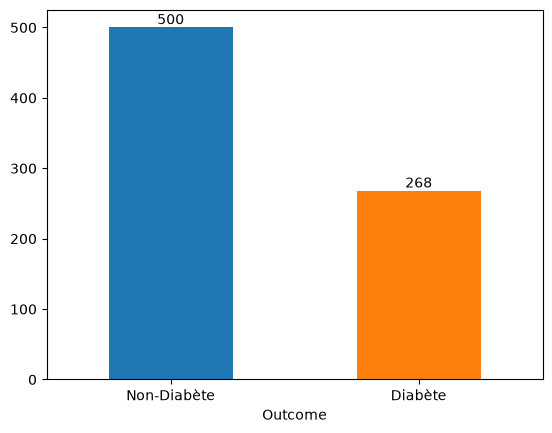

In [121]:
bar = df['Outcome'].value_counts().plot(kind='bar', color=['#1f77b4', '#ff7f0e'])
bar.set_xticklabels(['Non-Diabète', 'Diabète'], rotation=0)
bar.bar_label(bar.containers[0])


Les classes sont **déséquilibrées** : 500 non diabétiques (65 %) pour 268 diabétiques (35 %).

Conséquences pour la suite :

- **Référence minimale** : un modèle qui répondrait toujours « non diabétique » aurait déjà **65 % d'accuracy**. L'accuracy seule est donc trompeuse ; on suivra aussi le **recall** de la classe 1 (part des diabétiques détectées), le **F1** et l'**AUC ROC**.
- **Stratification** : les découpages en plis doivent conserver la proportion 65/35 dans chaque pli.

### Moyennes par classe

In [122]:
df.groupby('Outcome').mean().round(2)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
Outcome,,,,,,,,
0,3.30,110.68,70.92,27.73,127.79,30.89,0.43,31.19
1,4.87,142.13,75.12,31.69,164.70,35.38,0.55,37.07


<Axes: xlabel='Outcome'>

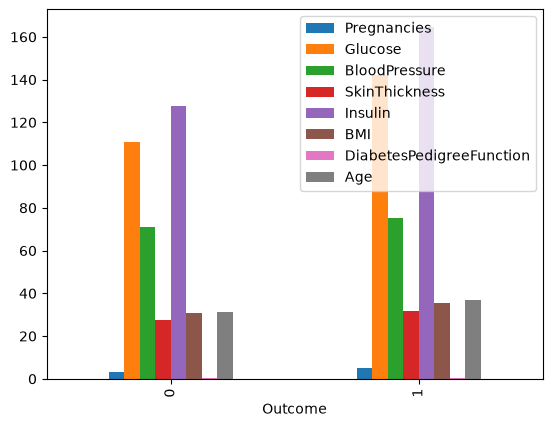

In [123]:
df.groupby('Outcome').mean().round(2).plot.bar()

Les moyennes confirment les boîtes à moustaches : les diabétiques ont en moyenne une glycémie plus haute (142 contre 111 mg/dL), un IMC plus élevé (35,4 contre 30,9) et sont plus âgées (37 contre 31 ans).

ℹ️ Dans le diagramme en barres, `Insulin` et `Glucose` écrasent les autres variables à cause de leur échelle. Le tableau est plus lisible que le graphique pour comparer les deux classes.

### Corrélations entre variables

<Axes: >

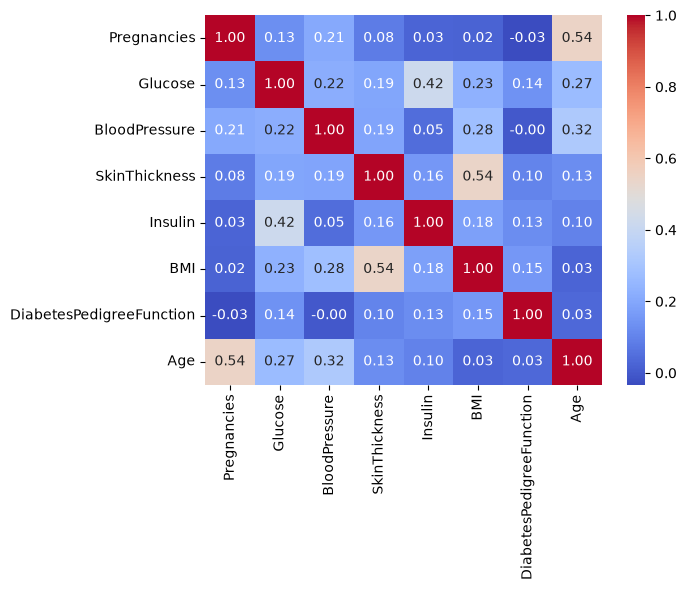

In [124]:
y = df['Outcome']
X = df.drop('Outcome', axis=1)

sns.heatmap(X.corr(), annot=True, cmap='coolwarm', fmt='.2f')

**Lecture de la matrice de corrélation**

- **Corrélations entre variables explicatives** : les plus fortes sont modérées. `Pregnancies` et `Age` sont à 0,54 (plus on est âgée, plus on a eu de grossesses). `SkinThickness` et `BMI` sont aussi à 0,54 (les deux mesurent la corpulence). Vient ensuite `Glucose` et `Insulin` à 0,42. Il n'y a **pas de redondance forte** : on garde toutes les variables.
- **Corrélation avec la cible** (non affichée sur la carte, qui exclut `Outcome`) : `Glucose` 0,49, `BMI` 0,31, `Age` 0,24, `Pregnancies` 0,22, puis les autres autour de 0,2. Le glucose est de loin le meilleur prédicteur individuel.

## 4. Premier essai de modélisation (découpage unique 70/30)

On sépare les données en 70 % pour l'entraînement (537 patientes) et 30 % pour le test (231 patientes), puis on entraîne les quatre modèles avec leurs **hyperparamètres par défaut**.


In [153]:
import sklearn.model_selection as model_selection

X_train, X_test, y_train, y_test = model_selection.train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)


In [154]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report
from sklearn.preprocessing import StandardScaler

modeles = {
    "Régression logistique": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "SVM": make_pipeline(StandardScaler(), SVC()),
    "Arbre de décision": DecisionTreeClassifier(random_state=42),
    "Réseau de neurones": make_pipeline(StandardScaler(), MLPClassifier(max_iter=3000, random_state=42)),
}

for nom, m in modeles.items():
    m.fit(X_train, y_train)
    print(f"--- {nom} ---")
    print(classification_report(y_test, m.predict(X_test)))

--- Régression logistique ---
              precision    recall  f1-score   support

           0       0.77      0.86      0.81       150
           1       0.67      0.53      0.59        81

    accuracy                           0.74       231
   macro avg       0.72      0.70      0.70       231
weighted avg       0.74      0.74      0.74       231

--- SVM ---
              precision    recall  f1-score   support

           0       0.76      0.87      0.81       150
           1       0.67      0.51      0.58        81

    accuracy                           0.74       231
   macro avg       0.72      0.69      0.69       231
weighted avg       0.73      0.74      0.73       231

--- Arbre de décision ---
              precision    recall  f1-score   support

           0       0.75      0.78      0.77       150
           1       0.57      0.53      0.55        81

    accuracy                           0.69       231
   macro avg       0.66      0.66      0.66       231
weight

**Lecture des résultats**

| Modèle | Accuracy | Recall (classe 1) | F1 (classe 1) |
|---|---|---|---|
| Régression logistique | 0,74 | 0,59 | 0,61 |
| SVM | 0,74 | 0,57 | 0,61 |
| Réseau de neurones | 0,71 | 0,59 | 0,58 |
| Arbre de décision | 0,70 | 0,60 | 0,58 |

- **Classe « non diabétique »** : tous les modèles la reconnaissent bien (recall de 0,75 à 0,83).
- **Classe « diabétique »** : environ **40 % des diabétiques ne sont pas détectées** (recall autour de 0,6). Pour un outil de dépistage, c'est le point faible principal.
- **Pourquoi aller plus loin** : ces chiffres reposent sur **un seul** découpage de 231 patientes, dont seulement 80 diabétiques. Avec un autre `random_state`, le classement des modèles pourrait changer. Les hyperparamètres n'ont pas non plus été réglés. La section suivante corrige ces deux points.

## 5. Réglage des hyperparamètres (GridSearchCV) et comparaison en validation croisée

Le découpage unique 70/30 ci-dessus donne des scores qui dépendent beaucoup du hasard du découpage (231 patientes en test).
On utilise ici une **validation croisée imbriquée** :

- **boucle interne** : `GridSearchCV` (5 plis) choisit les hyperparamètres en maximisant l'AUC ROC ;
- **boucle externe** : `cross_validate` (5 plis stratifiés) mesure la performance du modèle réglé sur des plis qu'il n'a jamais vus.

L'imputation des valeurs manquantes par la médiane est placée dans le pipeline, pour être apprise uniquement sur les données d'entraînement de chaque pli.

**Pourquoi l'AUC ROC pour le réglage ?** Elle mesure la capacité du modèle à donner un score plus élevé aux diabétiques qu'aux non-diabétiques, **quel que soit le seuil de décision**. Elle est aussi peu sensible au déséquilibre des classes. Le seuil pourra ensuite être ajusté selon l'usage médical : un dépistage privilégie le recall.

Hyperparamètres explorés :

| Modèle | Grille |
|---|---|
| Régression logistique | `C` |
| SVM | `C` × `kernel` (linear, rbf, poly, sigmoid) |
| Arbre de décision | `max_depth` |
| Réseau de neurones | `hidden_layer_sizes` (1 ou 2 couches cachées) |

⏱️ Le réseau de neurones prend environ 3 minutes. Les `ConvergenceWarning` proviennent des plus gros réseaux, qui ne sont de toute façon pas retenus.

In [155]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate

# Données brutes : les zéros impossibles deviennent NaN, mais l'imputation par la médiane
# est faite DANS le pipeline, donc recalculée sur chaque pli d'entraînement (pas de fuite).
df_brut = pd.read_csv('data/diabetes.csv')
df_brut[cols] = df_brut[cols].replace(0, np.nan)
X_brut = df_brut.drop('Outcome', axis=1)
y_brut = df_brut['Outcome']

def creer_pipeline(clf, normaliser=True):
    etapes = [('imputer', SimpleImputer(strategy='median'))]
    if normaliser:
        etapes.append(('scaler', StandardScaler()))
    etapes.append(('clf', clf))
    return Pipeline(etapes)

# (pipeline, grille d'hyperparamètres) pour chaque modèle
configs = {
    "Régression logistique": (
        creer_pipeline(LogisticRegression(max_iter=1000)),
        {'clf__C': [0.01, 0.1, 1, 10, 100]},
    ),
    "SVM": (
        creer_pipeline(SVC()),
        {'clf__C': [0.1, 1, 10, 100],
         'clf__kernel': ['linear', 'rbf', 'poly', 'sigmoid']},
    ),
    "Arbre de décision": (
        creer_pipeline(DecisionTreeClassifier(random_state=42), normaliser=False),
        {'clf__max_depth': [2, 3, 4, 5, 6, 7, 8, 10, None]},
    ),
    "Réseau de neurones": (
        creer_pipeline(MLPClassifier(max_iter=5000, random_state=42)),
        {'clf__hidden_layer_sizes': [(8,), (16,), (32,), (64,), (16, 8), (32, 16), (64, 32)]},
    ),
}

In [144]:
import time

# Validation croisée imbriquée :
#  - boucle interne (cv_interne) : GridSearchCV choisit les hyperparamètres
#  - boucle externe (cv_externe) : évalue le modèle ainsi réglé sur des données jamais vues pendant le réglage
cv_interne = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
cv_externe = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

resultats = {}
for nom, (pipeline, grille) in configs.items():
    debut = time.time()
    recherche = GridSearchCV(pipeline, grille, cv=cv_interne, scoring='roc_auc', n_jobs=-1)
    resultats[nom] = cross_validate(recherche, X_brut, y_brut, cv=cv_externe,
                                    scoring=scoring, return_estimator=True, n_jobs=-1)
    print(f"{nom:<22} terminé en {time.time() - debut:.1f} s")

Régression logistique  terminé en 0.9 s
SVM                    terminé en 6.3 s
Arbre de décision      terminé en 1.2 s
Réseau de neurones     terminé en 194.9 s


In [156]:
# Tableau comparatif : moyenne ± écart-type sur les 5 plis externes (trié par AUC)
tableau = pd.DataFrame({
    nom: {m: f"{r[f'test_{m}'].mean():.3f} ± {r[f'test_{m}'].std():.3f}" for m in scoring}
    for nom, r in resultats.items()
}).T
ordre = sorted(resultats, key=lambda nom: resultats[nom]['test_roc_auc'].mean(), reverse=True)
tableau.loc[ordre]

,accuracy,precision,recall,f1,roc_auc
Réseau de neurones,0.764 ± 0.018,0.681 ± 0.051,0.627 ± 0.040,0.650 ± 0.014,0.838 ± 0.018
Régression logistique,0.776 ± 0.016,0.735 ± 0.061,0.575 ± 0.048,0.641 ± 0.020,0.837 ± 0.021
SVM,0.772 ± 0.018,0.736 ± 0.069,0.556 ± 0.044,0.630 ± 0.023,0.831 ± 0.018
Arbre de décision,0.725 ± 0.028,0.605 ± 0.041,0.642 ± 0.106,0.617 ± 0.046,0.772 ± 0.025


**Lecture du tableau** (moyenne ± écart-type sur les 5 plis externes)

- **Trois modèles à égalité** : réseau de neurones (AUC 0,838), régression logistique (0,837) et SVM (0,831). Leurs écarts sont bien plus petits que leur écart-type (environ 0,02) : on **ne peut pas les départager** sur ces données.
- **L'arbre de décision est nettement en retrait** (AUC 0,772), et il est le plus instable : son recall varie de ± 0,106 d'un pli à l'autre.
- **Gain par rapport à la section 4** : l'accuracy passe d'environ 0,74 à 0,77 pour la régression logistique et le SVM. L'estimation est aussi plus fiable, car elle est moyennée sur les 768 patientes au lieu de 231.
- **Compromis précision / recall** :
  - la régression logistique et le SVM sont plus **précis** (≈ 0,74 : quand ils annoncent un diabète, ils ont raison 3 fois sur 4) mais détectent moins de diabétiques (recall ≈ 0,56–0,58) ;
  - le réseau de neurones détecte un peu plus de diabétiques (recall 0,63) au prix de plus de fausses alertes.

### Variabilité des scores d'un pli à l'autre

Chaque point noir est le score d'un pli externe.

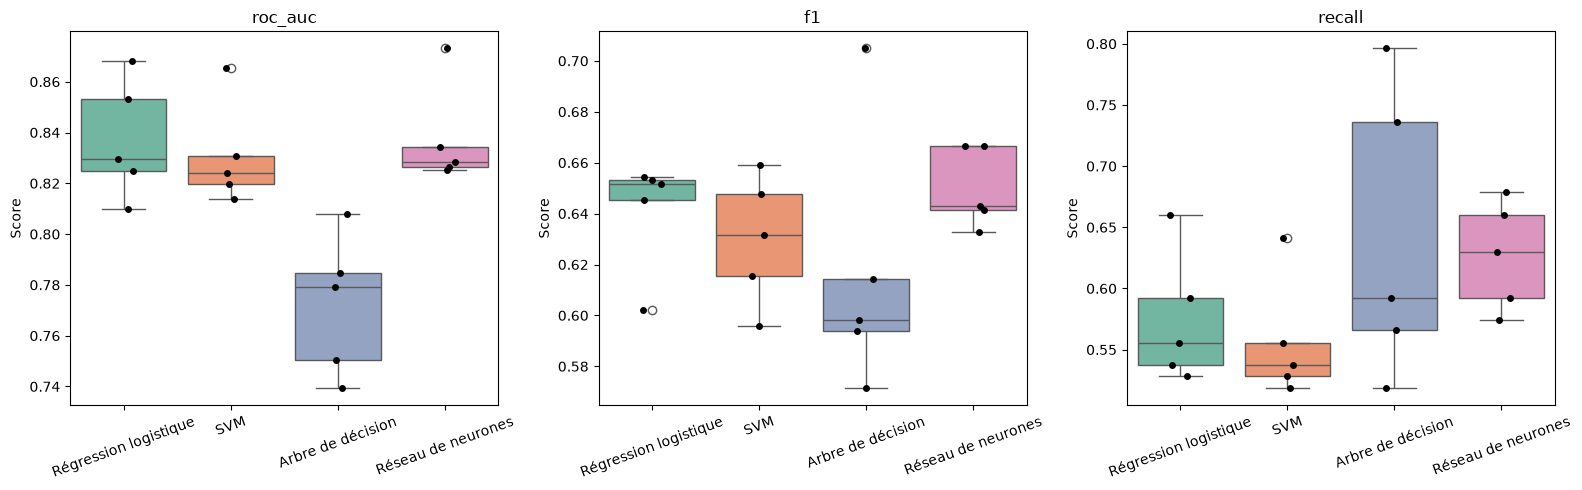

In [157]:
# Distribution des scores sur les plis externes
scores_long = pd.DataFrame([
    {'Modèle': nom, 'Métrique': m, 'Score': s}
    for nom, r in resultats.items()
    for m in ['roc_auc', 'f1', 'recall']
    for s in r[f'test_{m}']
])

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, m in zip(axes, ['roc_auc', 'f1', 'recall']):
    sous = scores_long[scores_long['Métrique'] == m]
    sns.boxplot(data=sous, x='Modèle', y='Score', hue='Modèle', palette='Set2', legend=False, ax=ax)
    sns.stripplot(data=sous, x='Modèle', y='Score', color='black', size=5, ax=ax)
    ax.set_title(m)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

Les boîtes des trois meilleurs modèles se chevauchent presque entièrement, ce qui confirme qu'ils se valent. Celle de l'arbre est plus basse en AUC et très étalée en recall.

### Courbes ROC

Chaque courbe montre, pour tous les seuils de décision possibles, le compromis entre :

- la part de diabétiques détectées (axe vertical, recall) ;
- la part de non-diabétiques signalées à tort (axe horizontal).

Plus la courbe s'approche du coin supérieur gauche, meilleur est le modèle. La diagonale grise correspond au hasard. Les courbes sont calculées sur les plis externes, avec les modèles déjà entraînés plus haut (aucun réentraînement).

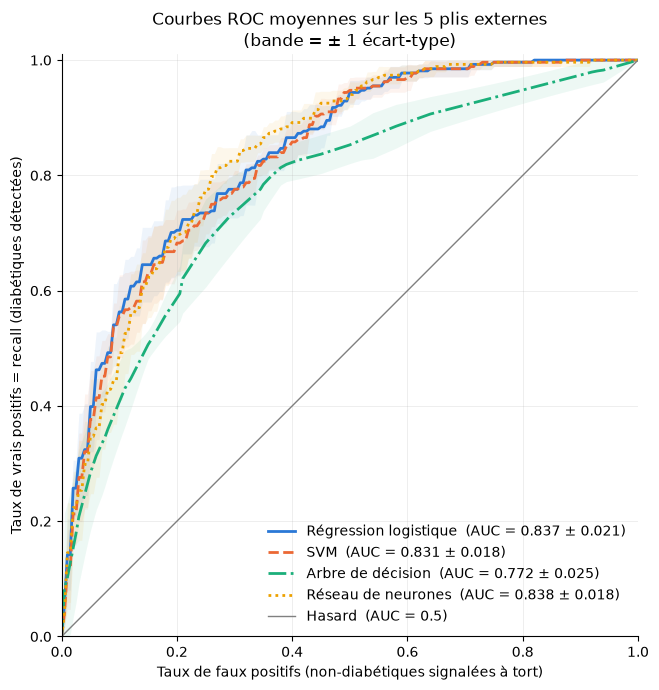

In [158]:
from sklearn.metrics import roc_curve, auc

plis = list(cv_externe.split(X_brut, y_brut))

def scores_positifs(modele, X):
    """Score de la classe 1 : decision_function si disponible (SVM, régression logistique), sinon predict_proba."""
    if hasattr(modele, 'decision_function'):
        return modele.decision_function(X)
    return modele.predict_proba(X)[:, 1]

fpr_grille = np.linspace(0, 1, 201)
couleurs = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']   # bleu, orange, vert d'eau, jaune
styles = ['-', '--', '-.', (0, (1, 1.5))]                 # style de trait en plus de la couleur

fig, ax = plt.subplots(figsize=(7, 7))
for (nom, r), couleur, style in zip(resultats.items(), couleurs, styles):
    tprs, aucs = [], []
    for est, (_, idx_test) in zip(r['estimator'], plis):
        fpr, tpr, _ = roc_curve(y_brut.iloc[idx_test], scores_positifs(est, X_brut.iloc[idx_test]))
        tpr_interp = np.interp(fpr_grille, fpr, tpr)
        tpr_interp[0] = 0.0
        tprs.append(tpr_interp)
        aucs.append(auc(fpr, tpr))
    tpr_moyen, tpr_ecart = np.mean(tprs, axis=0), np.std(tprs, axis=0)
    tpr_moyen[-1] = 1.0

    ax.plot(fpr_grille, tpr_moyen, color=couleur, linestyle=style, linewidth=2,
            label=f"{nom}  (AUC = {np.mean(aucs):.3f} ± {np.std(aucs):.3f})")
    ax.fill_between(fpr_grille, np.clip(tpr_moyen - tpr_ecart, 0, 1), np.clip(tpr_moyen + tpr_ecart, 0, 1),
                    color=couleur, alpha=0.08, linewidth=0)

ax.plot([0, 1], [0, 1], color='grey', linewidth=1, label='Hasard  (AUC = 0.5)')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.01)
ax.set_aspect('equal')
ax.set_xlabel('Taux de faux positifs (non-diabétiques signalées à tort)')
ax.set_ylabel('Taux de vrais positifs = recall (diabétiques détectées)')
ax.set_title('Courbes ROC moyennes sur les 5 plis externes\n(bande = ± 1 écart-type)')
ax.grid(alpha=0.3, linewidth=0.5)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(loc='lower right', frameon=False)
plt.tight_layout()
plt.show()

**Lecture des courbes ROC**

- **Trois courbes superposées** : régression logistique, SVM et réseau de neurones sont quasiment confondues sur toute la plage.
- **L'arbre est en dessous presque partout.** Par exemple, pour 20 % de faux positifs, il détecte environ 60 % des diabétiques, contre environ 70 % pour les trois autres.
- **Prix d'un dépistage exigeant** : pour détecter 90 % des diabétiques avec les meilleurs modèles, il faut accepter environ 45 % de fausses alertes.

### Stabilité des hyperparamètres choisis

In [159]:
# Hyperparamètres choisis par GridSearchCV dans chaque pli externe (stabilité du réglage)
params_par_pli = pd.DataFrame({
    nom: [str({k.replace('clf__', ''): v for k, v in est.best_params_.items()}) for est in r['estimator']]
    for nom, r in resultats.items()
}, index=[f"Pli {i + 1}" for i in range(cv_externe.get_n_splits())])
params_par_pli

,Régression logistique,SVM,Arbre de décision,Réseau de neurones
Pli 1,{'C': 10},"{'C': 0.1, 'kernel': 'linear'}",{'max_depth': 4},"{'hidden_layer_sizes': (8,)}"
Pli 2,{'C': 0.1},"{'C': 0.1, 'kernel': 'sigmoid'}",{'max_depth': 4},"{'hidden_layer_sizes': (16,)}"
Pli 3,{'C': 0.1},"{'C': 1, 'kernel': 'rbf'}",{'max_depth': 5},"{'hidden_layer_sizes': (16,)}"
Pli 4,{'C': 0.1},"{'C': 0.1, 'kernel': 'linear'}",{'max_depth': 3},"{'hidden_layer_sizes': (8,)}"
Pli 5,{'C': 1},"{'C': 1, 'kernel': 'linear'}",{'max_depth': 4},"{'hidden_layer_sizes': (16,)}"


**Lecture du tableau**

- **Arbre de décision** : très stable, avec une profondeur de 4 dans 3 plis sur 5 (3 ou 5 sinon). Un arbre peu profond suffit ; au-delà, il apprend le bruit.
- **SVM** : le noyau **linéaire** domine (3 plis sur 5), avec un `C` faible (0,1 ou 1), donc une régularisation assez forte. Le SVM se comporte alors comme une régression logistique, d'où leurs scores très proches.
- **Régression logistique** : `C = 0,1` dans 3 plis sur 5, là aussi une régularisation assez forte.
- **Réseau de neurones** : les petits réseaux (8 ou 16 neurones, une seule couche) sont toujours préférés. Avec 768 patientes, un réseau plus gros n'apporte rien.

Globalement, sur ce jeu de données, **des modèles simples et régularisés suffisent**.

### Hyperparamètres retenus et modèles finaux

Si les hyperparamètres choisis changent d'un pli externe à l'autre, c'est que plusieurs réglages se valent sur ces données.
Les scores de la validation croisée imbriquée estiment la performance de **toute la procédure** (réglage + entraînement).
Pour obtenir les modèles à utiliser, on relance enfin `GridSearchCV` sur l'ensemble du jeu de données.
Son `best_score_` est optimiste, puisqu'il a servi à choisir les paramètres : c'est le tableau ci-dessus qui fait foi pour comparer les modèles.

In [148]:
# Modèles finaux : GridSearchCV sur toutes les données pour fixer les hyperparamètres
modeles_finaux = {}
for nom, (pipeline, grille) in configs.items():
    gs = GridSearchCV(pipeline, grille, cv=cv_interne, scoring='roc_auc', n_jobs=-1)
    gs.fit(X_brut, y_brut)
    modeles_finaux[nom] = gs.best_estimator_
    print(f"{nom:<22} AUC (CV interne) = {gs.best_score_:.3f}  ->  {gs.best_params_}")

Régression logistique  AUC (CV interne) = 0.837  ->  {'clf__C': 0.1}
SVM                    AUC (CV interne) = 0.837  ->  {'clf__C': 0.1, 'clf__kernel': 'linear'}
Arbre de décision      AUC (CV interne) = 0.792  ->  {'clf__max_depth': 4}
Réseau de neurones     AUC (CV interne) = 0.836  ->  {'clf__hidden_layer_sizes': (64,)}


Sur l'ensemble des données, les choix rejoignent ceux des plis : `C = 0,1`, SVM linéaire, profondeur 4. Seul le réseau de neurones choisit cette fois 64 neurones, alors que les plis préféraient 8 ou 16. Cela confirme que, pour ce modèle, plusieurs tailles donnent quasiment le même score.

## 6. Conclusion

**Résultats**

- **Meilleur niveau atteint** : une AUC ROC d'environ **0,84** et une accuracy d'environ **0,77** en validation croisée imbriquée. Cela correspond à 12 points de mieux que la référence de 65 % (toujours répondre « non diabétique »).
- **Trois modèles équivalents** : régression logistique, SVM et réseau de neurones obtiennent des performances statistiquement indiscernables. L'arbre de décision est nettement moins bon (AUC 0,77).
- **Modèle recommandé : la régression logistique.**
  - Elle est aussi performante que les autres et de loin la plus rapide à entraîner (moins d'une seconde, contre environ 3 minutes pour le réseau).
  - Elle est **interprétable** : ses coefficients indiquent le poids de chaque variable, un atout important dans un contexte médical.
- **Variable clé** : `Glucose`, suivie de `BMI` et `Age`.

**Limites**

- **Détection incomplète** : avec le seuil par défaut, environ 40 % des diabétiques ne sont pas détectées. Pour un usage de dépistage, il faudrait abaisser le seuil de décision et accepter plus de fausses alertes (voir les courbes ROC).
- **Imputation grossière** : la moitié des valeurs d'`Insulin` et près d'un tiers de celles de `SkinThickness` sont imputées par une valeur unique (la médiane).
- **Données restreintes** : 768 patientes d'une population très spécifique (femmes Pima de 21 ans et plus). Les résultats ne se généralisent pas tels quels à d'autres populations.

**Pistes d'amélioration**

- **Choisir un seuil de décision** adapté à l'objectif médical, par exemple pour atteindre un recall d'au moins 0,8.
- **Mieux traiter les valeurs manquantes** : `KNNImputer` ou `IterativeImputer`, ou un indicateur « valeur manquante » (`add_indicator=True`).
- **Rééquilibrer les classes** avec `class_weight='balanced'`.
- **Essayer des ensembles d'arbres** (forêt aléatoire, gradient boosting), généralement bien plus performants qu'un arbre seul.